# Exp 8: selectable population trajectories and distance from Control

Overlay selected stimulus means on a **single 2D or 3D plot per side**, with an
optional left/right overlay in genuinely shared PCA coordinates. Default display:
**Control, Seg 2, Seg 1, Seg 1/3/5, and one-position flicker**. Rocking remains
available. Edit `DISPLAY_STIMULI` to change the displayed subset without refitting.
There are no separate 0–4 s plots or individual repetition paths.

Quantify each selected condition **only against its same-side Control** and
overlay those distance curves through time.

This independent notebook uses the maintained eight-fish cohort, reviewed
continuous baseline z-scores, retained neuron IDs and B1–B4 acquisition order.
No Lab caches are written. Population-space examples:
[Zhao et al. (2026)](https://www.nature.com/articles/s41586-026-10623-3),
[IBL (2025)](https://www.nature.com/articles/s41586-025-09235-0).

In [58]:
from pathlib import Path
from importlib import reload
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
import src.data_loading as data_loading
import src.plotting_common as plot_common
import src.several_fish_loading as several_loading
import src.stimuli_timeline as timeline
import src.stimulus_similarity as similarity_core
similarity_core = reload(similarity_core)
import src.population_trajectories as population
import src.plotting_population_trajectories as population_plot
population, population_plot = reload(population), reload(population_plot)

## 1. Data and common coordinates

Each neuron contributes its continuous baseline-z-scored fluorescence averaged
over four repetitions. No binary threshold, smoothing, whitening, condition-wise
normalization, or per-trial baseline reset is applied. Keep the same original
neuron identities across fitted conditions within each fish; jointly exclude
and audit nonfinite neurons. Pool fish as distinct neuron features, weighting
each fish's columns by `1 / sqrt(number_of_fish × neurons_in_fish)` to balance
neuron counts. Biological response amplitudes can still differ between fish.

**Time zero is the common movement-program start**, 8 s after appearance. Fit
PCA on **[0, 8) s** to include delayed calcium responses, then project **0–14 s**
for the full movement period and 5 s after program end. The fit extension also
contains continued stimulation; it is not pure decay. Native sampling is 2 Hz.

Individual side plots retain their **per-side pooled PCA** (96 fit rows each).
The combined plot uses **one PCA fitted jointly to left and right conditions**
(192 rows), with common original neuron identities within each fish. Independent
PC rotations are never overlaid. Set `PCA_BASIS='joint'` below to also use joint
coordinates for individual side plots. There is no neuron matching between fish
and no fabricated simultaneous cross-fish trial. Display selection does not
change either basis. To change what determines the PCs, edit `FIT_STIMULI` and
rerun preparation.

In [59]:
USER_SETTINGS = {
    'experiment_name': 'Exp_8_accumulation_ev',
    'lab_root': data_loading.resolve_lab_root(),
    'fish_ids': ['L800_f02', 'L800_f03', 'L800_f09', 'L800_f04',
                 'L800_f05', 'L800_f07', 'L800_f10', 'L800_f11'],
    'selected_blocks': ['B1', 'B2', 'B3', 'B4'], 'verbose_loading': False,
    'timing': {'fps_2p': 2.0, 't_pre_s': 5.0, 't_post_s': 32.0},
    'stim_order': [5, 4, 3, 2, 1, 8, 7, 6, 16, 15, 14, 13, 12, 11, 10, 9],
}
CONTROLS = {'left': 'LeB', 'right': 'RiB'}
FIT_STIMULI = {
    'left': ['LeB', 'LeBseg2', 'LeBseg1', 'LeBseg135', 'LeRock', 'Leflick1'],
    'right': ['RiB', 'RiBseg2', 'RiBseg1', 'RiBseg135', 'RiBrock', 'RiBflick1'],
}
SIDE_CONDITIONS = {
    side: {'stimuli': labels, 'pairs': [(CONTROLS[side], label) for label in labels if label != CONTROLS[side]]}
    for side, labels in FIT_STIMULI.items()
}
PROGRAM_ONSET_S, PROGRAM_END_S, TRAJECTORY_FPS = 8.0, 9.0, 60.0
ANALYSIS_SETTINGS = {
    'program_onset_s': PROGRAM_ONSET_S, 'window_s': (-1.0, 14.5),
    'fit_window_s': (0.0, 8.0), 'expected_reps': 4, 'n_components': 3, 'pca_scope': 'pooled',
}

### SVG destination

Each figure now has its **own True/False save switch at the top of its plotting
cell**. Running that cell draws and optionally saves only that figure. There is
no separate batch-export step. All SVGs use this portable Fig. 3 destination.

In [60]:
SVG_DIR = data_loading.resolve_lab_root() / 'Results/Paper/figures/main/fig03/assets/generated'

## 2. Prepare once

Joint fitting intersects finite original neuron identities across sides within
each fish, retaining the first side's order. The audit makes additional exclusions
visible. The combined overlay uses the joint fit; individual side plots follow
`PCA_BASIS`. Full-space distance calculations
remain within fish and independent of the PCA projection.

In [61]:
raster_inputs = several_loading.load_and_preflight_fish_raster_inputs(USER_SETTINGS)
all_fish_data = raster_inputs['all_fish_data']
fish_ids, timing = raster_inputs['fish_ids'], raster_inputs['timing']
stimuli_path = raster_inputs['analysis_path'] / USER_SETTINGS['experiment_name'] / 'stimuli'
trajectory_result = population.build_population_trajectory_analysis(
    all_fish_data, fish_ids, SIDE_CONDITIONS,
    fps_2p=timing['fps_2p'], t_pre_s=timing['t_pre_s'], **ANALYSIS_SETTINGS,
)
joint_pca = population.build_joint_population_pca(trajectory_result, n_components=3)
display(joint_pca['joint_audit'])
pca_overview = pd.DataFrame([
    {'basis': name, 'neurons': len(fit['neuron_metadata']), 'fitted_rows': fit['pca'].n_samples_,
     'PC1_percent': 100 * fit['explained_variance_ratio'][0],
     'PC1_3_percent': 100 * fit['explained_variance_ratio'].sum()}
    for name, fit in {**trajectory_result['pooled_fits'], 'Joint left/right': joint_pca}.items()
])
display(pca_overview.round(2))

,fish_id,side,side_neurons,joint_neurons,excluded_from_joint
0,L800_f02,left,380,380,0
1,L800_f02,right,380,380,0
2,L800_f03,left,192,192,0
3,L800_f03,right,192,192,0
4,L800_f09,left,549,549,0
5,L800_f09,right,549,549,0
6,L800_f04,left,424,424,0
7,L800_f04,right,424,424,0
8,L800_f05,left,441,441,0
9,L800_f05,right,441,441,0


,basis,neurons,fitted_rows,PC1_percent,PC1_3_percent
0,left,3145,96,77.50,88.29
1,right,3145,96,78.47,88.00
2,Joint left/right,3145,192,55.73,85.23


## 3. Select stimuli and draw the full trajectories

**`DISPLAY_STIMULI` drives both the PCA and distance overlays.** Choose any subset
of the fitted labels per side, in the desired order. Rocking can be substituted
or added. The default five conditions include Control. To display only a joint
plot, set `PCA_LAYOUTS = ['both']`; to see one side, use `['left']` or `['right']`.

Each side uses its fixed per-side basis by default; the combined plot uses a
true joint fit. With `PCA_BASIS='joint'`, all layouts share the same fitted axes.
Color identifies stimulus family; on a joint plot **left is solid and right is
dashed**. Circles mark start, squares
end, and dots mark elapsed time. Numeric times label the first path in 2D.
Only mean paths are drawn. After editing shared selections or appearance, run the
settings cell below, then the individual figure cell you want to redraw and save.

In [62]:
DISPLAY_STIMULI = {
    'left': ['LeB', 'LeBseg2', 'LeBseg1', 'LeBseg135', 'Leflick1'],
    'right': ['RiB', 'RiBseg2', 'RiBseg1', 'RiBseg135', 'RiBflick1'],
}
PCA_LAYOUTS = ['left', 'right', 'both']
PCA_BASIS = 'per_side'  # Or 'joint'; the combined plot always uses joint axes.
PCA_VIEWS = [(0, 1), (0, 1, 2)]  # Zero-based PCs; try (0, 2) or (1, 2).
DISPLAY_WINDOW_S = (0.0, 14.0)
PCA_2D_FIGSIZE, PCA_3D_FIGSIZE, PCA_FONT_PT = (9, 6), (10, 7.5), 9
CONDITION_COLORS = {
    'LeB': '#293F50', 'RiB': '#293F50', 'LeBseg2': '#4F947F', 'RiBseg2': '#4F947F',
    'LeBseg1': '#BE7844', 'RiBseg1': '#BE7844', 'LeBseg135': '#8C6BB1', 'RiBseg135': '#8C6BB1',
    'LeRock': '#B35574', 'RiBrock': '#B35574', 'Leflick1': '#569BB9', 'RiBflick1': '#569BB9',
}
# Shared display preparation only; no analysis or PCA is recalculated here.
PCA_OVERLAY_SETTINGS = {}
for layout in PCA_LAYOUTS:
    sides = list(DISPLAY_STIMULI) if layout == 'both' else [layout]
    fit = joint_pca if layout == 'both' or PCA_BASIS == 'joint' else trajectory_result['pooled_fits'][layout]
    keys = ([(side, label) for side in sides for label in DISPLAY_STIMULI[side]]
            if 'sides' in fit else DISPLAY_STIMULI[layout])
    key_labels = {key: key[1] if isinstance(key, tuple) else key for key in keys}
    PCA_OVERLAY_SETTINGS[layout] = {
        'side': 'left + right' if layout == 'both' else layout, 'groups': {'': keys},
        'pca_fit': fit, 'time_window_s': DISPLAY_WINDOW_S, 'focus_window_s': None,
        'colors': {key: CONDITION_COLORS[label] for key, label in key_labels.items()},
        'line_styles': {key: '--' if layout == 'both' and key[0] == 'right' else '-' for key in keys},
        'legend_labels': key_labels, 'legend_columns': 2 if layout == 'both' else 1,
        'marker_interval_s': 4.0,
        'title': 'Joint left/right PCA' if 'sides' in fit else f'{layout.capitalize()} PCA',
    }
pca_figures = {}


### Left PCA — 2D

Set `SAVE_PCA_LEFT_2D_SVG` below to `True` or `False`, then run this cell.

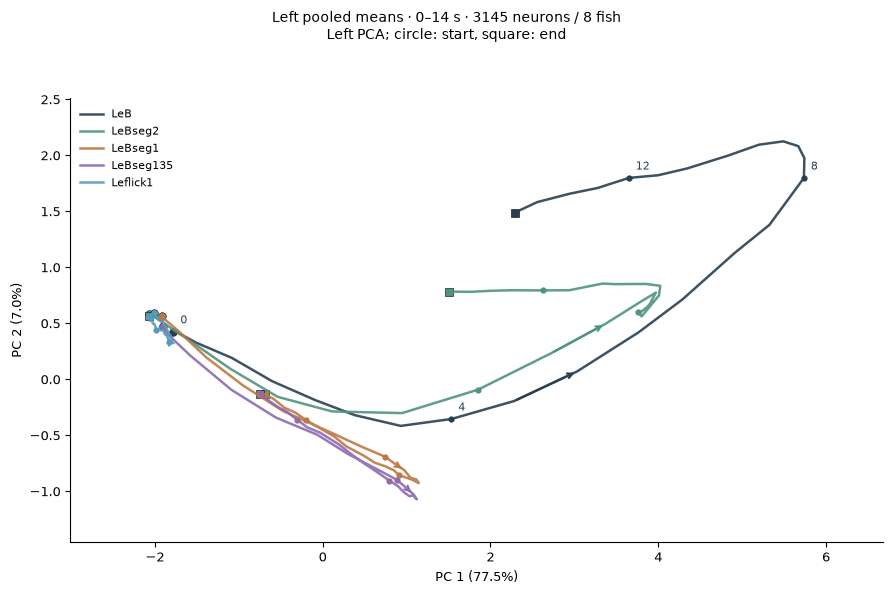

Saved SVG: exp08_population_pca_left_2d.svg


In [63]:
SAVE_PCA_LEFT_2D_SVG = True  # Save only this figure as SVG.
if 'left' in PCA_LAYOUTS and any(len(view) == 2 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 2)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **PCA_OVERLAY_SETTINGS['left'], dimensions=dimensions,
        figsize=PCA_2D_FIGSIZE, font_size=PCA_FONT_PT,
    )
    pca_figures[('left', 2)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_LEFT_2D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_left_2d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

### Left PCA — 3D

Set `SAVE_PCA_LEFT_3D_SVG` below to `True` or `False`, then run this cell.

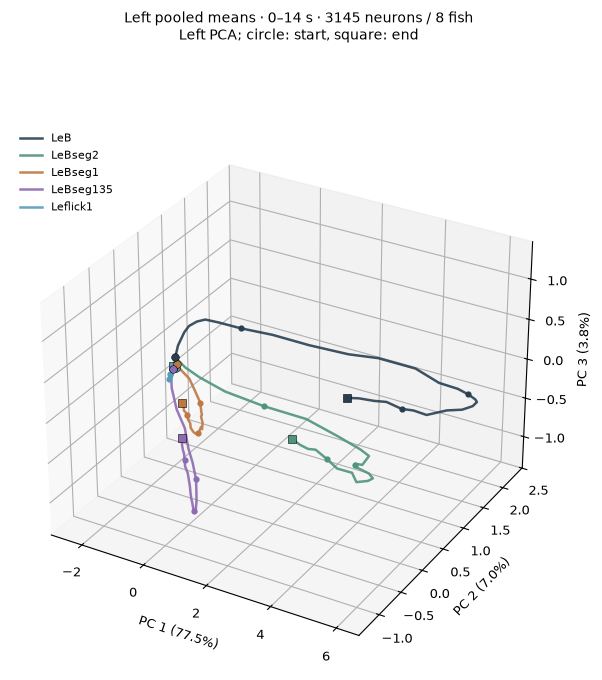

Saved SVG: exp08_population_pca_left_3d.svg


In [64]:
SAVE_PCA_LEFT_3D_SVG = True  # Save only this figure as SVG.
if 'left' in PCA_LAYOUTS and any(len(view) == 3 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 3)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **PCA_OVERLAY_SETTINGS['left'], dimensions=dimensions,
        figsize=PCA_3D_FIGSIZE, font_size=PCA_FONT_PT,
    )
    pca_figures[('left', 3)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_LEFT_3D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_left_3d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

### Right PCA — 2D

Set `SAVE_PCA_RIGHT_2D_SVG` below to `True` or `False`, then run this cell.

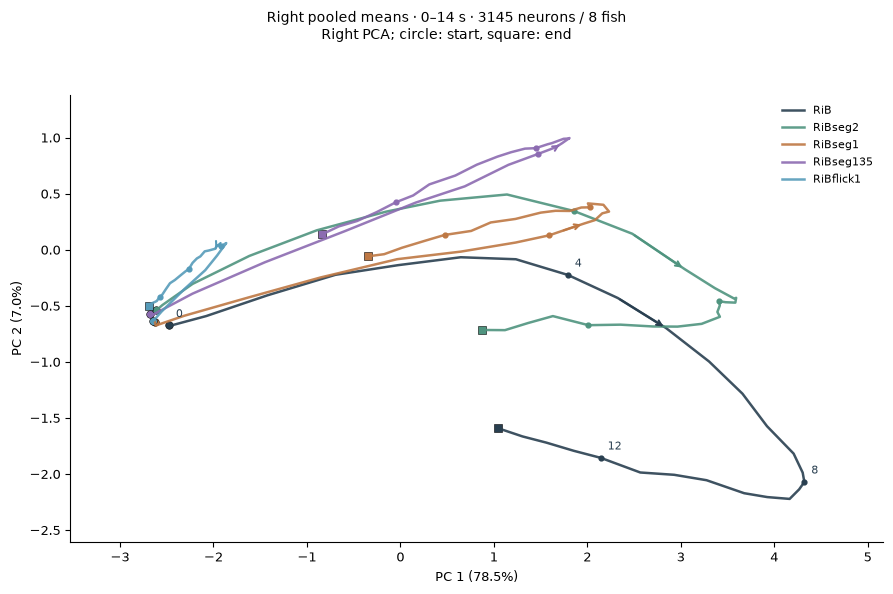

Saved SVG: exp08_population_pca_right_2d.svg


In [65]:
SAVE_PCA_RIGHT_2D_SVG = True  # Save only this figure as SVG.
if 'right' in PCA_LAYOUTS and any(len(view) == 2 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 2)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **PCA_OVERLAY_SETTINGS['right'], dimensions=dimensions,
        figsize=PCA_2D_FIGSIZE, font_size=PCA_FONT_PT,
    )
    pca_figures[('right', 2)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_RIGHT_2D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_right_2d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

### Right PCA — 3D

Set `SAVE_PCA_RIGHT_3D_SVG` below to `True` or `False`, then run this cell.

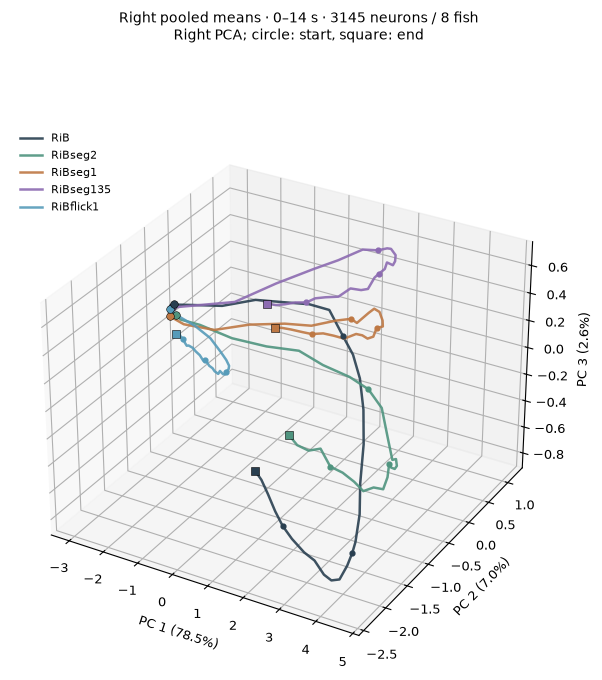

Saved SVG: exp08_population_pca_right_3d.svg


In [66]:
SAVE_PCA_RIGHT_3D_SVG = True  # Save only this figure as SVG.
if 'right' in PCA_LAYOUTS and any(len(view) == 3 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 3)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **PCA_OVERLAY_SETTINGS['right'], dimensions=dimensions,
        figsize=PCA_3D_FIGSIZE, font_size=PCA_FONT_PT,
    )
    pca_figures[('right', 3)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_RIGHT_3D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_right_3d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

### Left + right PCA — 2D

Set `SAVE_PCA_BOTH_2D_SVG` below to `True` or `False`, then run this cell.

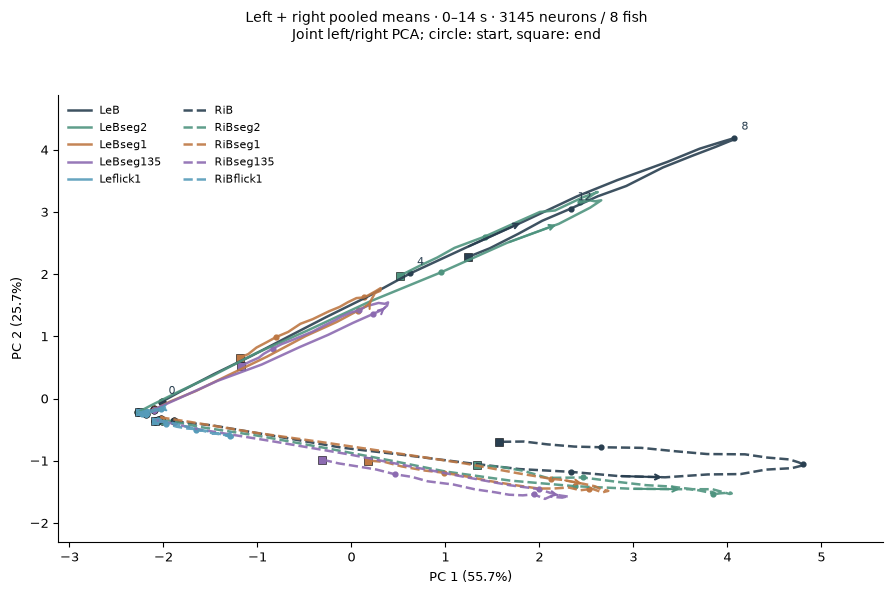

Saved SVG: exp08_population_pca_both_2d.svg


In [67]:
SAVE_PCA_BOTH_2D_SVG = True  # Save only this figure as SVG.
if 'both' in PCA_LAYOUTS and any(len(view) == 2 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 2)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **PCA_OVERLAY_SETTINGS['both'], dimensions=dimensions,
        figsize=PCA_2D_FIGSIZE, font_size=PCA_FONT_PT,
    )
    pca_figures[('both', 2)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_BOTH_2D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_both_2d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

### Left + right PCA — 3D

Change `PCA_BOTH_3D_FIGSIZE` (width, height in inches) below to resize this figure.
`PCA_BOTH_3D_FONT_PT` controls axes/title text; `PCA_BOTH_3D_LEGEND_FONT_PT` controls
legend text independently. Set the legend columns and location here as well.
An optional legend anchor such as `(0.02, 0.98)` positions it in axes coordinates;
`None` uses the location alone. These controls affect only this combined 3D plot.

Set `SAVE_PCA_BOTH_3D_SVG` to `True` or `False`, then rerun this cell to redraw and
optionally save the figure without refitting the PCA.


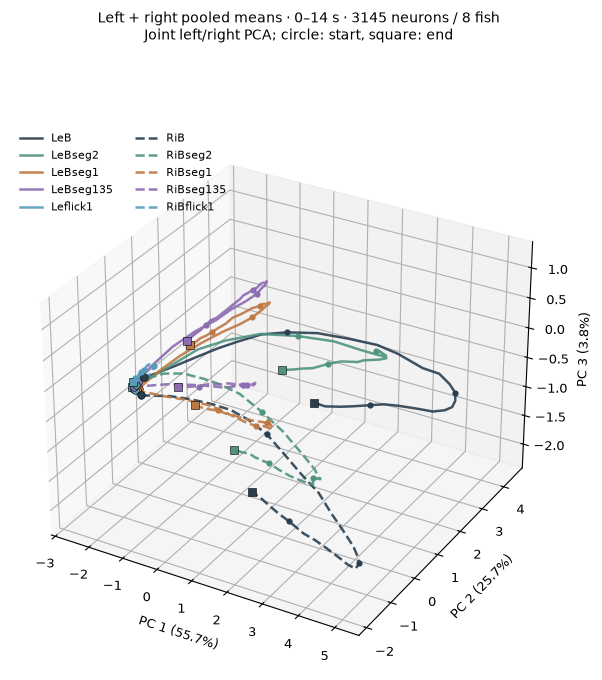

Saved SVG: exp08_population_pca_both_3d.svg


In [68]:
SAVE_PCA_BOTH_3D_SVG = True  # Save only this figure as SVG.
PCA_BOTH_3D_FIGSIZE = (10, 7.5)  # Width, height in inches.
PCA_BOTH_3D_FONT_PT = 9
PCA_BOTH_3D_LEGEND_FONT_PT = 8
PCA_BOTH_3D_LEGEND_COLUMNS = 2
PCA_BOTH_3D_LEGEND_LOC = 'upper left'
PCA_BOTH_3D_LEGEND_ANCHOR = None  # Or (0.02, 0.98), in axes coordinates.
if 'both' in PCA_LAYOUTS and any(len(view) == 3 for view in PCA_VIEWS):
    dimensions = next(view for view in reversed(PCA_VIEWS) if len(view) == 3)
    plotted = population_plot.plot_pooled_population_trajectories(
        trajectory_result, **{**PCA_OVERLAY_SETTINGS['both'], 'legend_columns': PCA_BOTH_3D_LEGEND_COLUMNS},
        dimensions=dimensions, figsize=PCA_BOTH_3D_FIGSIZE, font_size=PCA_BOTH_3D_FONT_PT,
        legend_font_size=PCA_BOTH_3D_LEGEND_FONT_PT, legend_loc=PCA_BOTH_3D_LEGEND_LOC,
        legend_bbox_to_anchor=PCA_BOTH_3D_LEGEND_ANCHOR,
    )
    pca_figures[('both', 3)] = plotted
    display(plotted['figure'])
    if SAVE_PCA_BOTH_3D_SVG:
        saved_svg = plot_common.save_publication_figure(
            plotted['figure'], SVG_DIR / 'exp08_population_pca_both_3d', formats=('svg',),
        )
        print(f'Saved SVG: {saved_svg[0].name}')
    plt.close(plotted['figure'])

## 4. Quantify difference only from same-side Control

Use the **crossvalidated squared population distance** in the full neuron space:
average products of condition differences across distinct B1–B4 blocks, per
neuron within fish, then average fish equally. Negative estimates are retained;
no square root or clipping is applied. This measures repeat-consistent activity
differences, including gain and recruitment, independently of displayed PCs.

Corrected evidence uses whole-block paired condition-label swaps, preserving
the complete time course. Maximum-over-time correction covers the full calculation
window; Bonferroni covers **all 10 configured stimulus-versus-Control comparisons**
across both sides, including fitted conditions hidden from display. Exchangeable
blocks and independent fish/blocks are assumptions. Display selection does not
change corrections. Control self-distance is the zero reference, not a reliability
test. There are no segment-versus-segment comparisons.

In [69]:
RUN_PERMUTATION_TEST = True
N_PERMUTATIONS, PERMUTATION_SEED, ALPHA = 5000, 8, 0.05
separation_evidence = (
    population.test_population_separation(
        trajectory_result, n_permutations=N_PERMUTATIONS, seed=PERMUTATION_SEED, alpha=ALPHA,
    ) if RUN_PERMUTATION_TEST else None
)

### Overlay distance curves from Control

Selected non-control stimuli are overlaid per side through the same display
window as the trajectories. The x-axis is **Time from stimulus motion onset (s)**,
using the common 8 s motion-program anchor, rather than each condition's first
coordinate change. Curves show equal-fish means with descriptive SEM;
the dotted line marks movement-program end. Detection statistics are returned
in the table below, without significance markers or evidence annotations on the
plot. This does not test differences between two non-control distance curves.

Set `COMBINE_DISTANCE_SIDES=True` for one axes with solid left/dashed right curves.
Use `DISTANCE_Y_SCALE='symlog'` if the large flicker distance obscures smaller
differences; zero and negative estimates are retained.

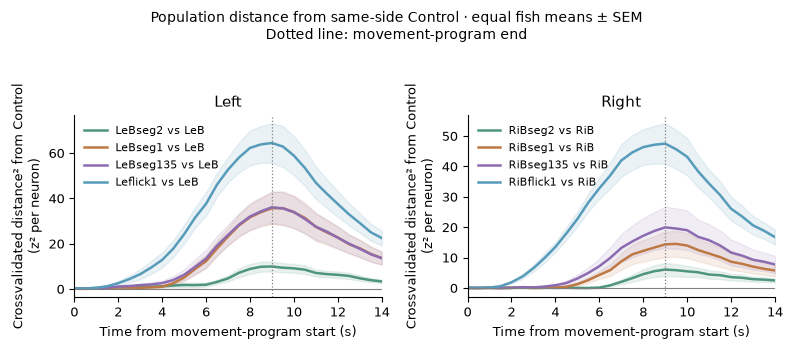

Saved SVG: exp08_population_distance_to_control.svg


,side,control,stimulus,first_corrected_evidence_s
0,left,LeB,LeBseg2,7.5
1,left,LeB,LeBseg1,7.0
2,left,LeB,LeBseg135,6.5
3,left,LeB,Leflick1,6.0
4,right,RiB,RiBseg2,8.0
5,right,RiB,RiBseg1,7.0
6,right,RiB,RiBseg135,7.0
7,right,RiB,RiBflick1,5.5


In [75]:
SAVE_DISTANCE_SVG = True  # Save only this figure as SVG.
COMBINE_DISTANCE_SIDES = False
SHOW_DISTANCE_SEM = True
DISTANCE_Y_SCALE = 'linear'  # Or 'symlog'; units remain z² per neuron.
DISTANCE_FIGSIZE, DISTANCE_FONT_PT = (8, 3.5), 9
distance_plot = population_plot.plot_control_distance_overlay(
    trajectory_result, CONTROLS, DISPLAY_STIMULI, significance=separation_evidence,
    colors=CONDITION_COLORS, time_window_s=DISPLAY_WINDOW_S, program_end_s=PROGRAM_END_S,
    combine_sides=COMBINE_DISTANCE_SIDES, show_sem=SHOW_DISTANCE_SEM,
    y_scale=DISTANCE_Y_SCALE, figsize=DISTANCE_FIGSIZE, font_size=DISTANCE_FONT_PT,
)
display(distance_plot['figure'])
if SAVE_DISTANCE_SVG:
    saved_svg = plot_common.save_publication_figure(
        distance_plot['figure'], SVG_DIR / 'exp08_population_distance_to_control', formats=('svg',),
    )
    print(f'Saved SVG: {saved_svg[0].name}')
plt.close(distance_plot['figure'])
evidence_summary = distance_plot['detection_table']
display(evidence_summary.round(3))

## 5. Pattern similarity at matching times

Compare the relative activity across the same neurons under each stimulus and
same-side Control, using Pearson correlation at each matching time. Positive
scaling or a common activity offset does not change this correlation. Values
range from -1 to +1; zero means no linear pattern correspondence. This calculation
uses the full neuron space without PCA, smoothing or temporal warping.

The default `split_half` estimator averages across the three balanced 2+2 block
partitions, comparing opposite stimulus/Control halves in both directions. Every
comparison uses two-repetition means, with all four repetitions contributing.
The gray Control repeatability curve uses matched repetition counts and is
descriptive, not a formal ceiling, significance threshold or equivalence test.

Set `SIMILARITY_ESTIMATOR='trial_mean'` for all-four-repetition mean responses;
the unmatched two-trial reference is then omitted. Average r across fish equally.
Constant population vectors yield NaN, with valid-fish counts retained.
`DISPLAY_STIMULI` selects the displayed conditions.

In [71]:
SIMILARITY_ESTIMATOR = 'split_half'  # Or 'trial_mean' for all-four-repetition means.
pattern_similarity = population.build_control_pattern_similarity(
    trajectory_result, CONTROLS, time_window_s=DISPLAY_WINDOW_S,
    estimator=SIMILARITY_ESTIMATOR, include_repeatability=True,
)

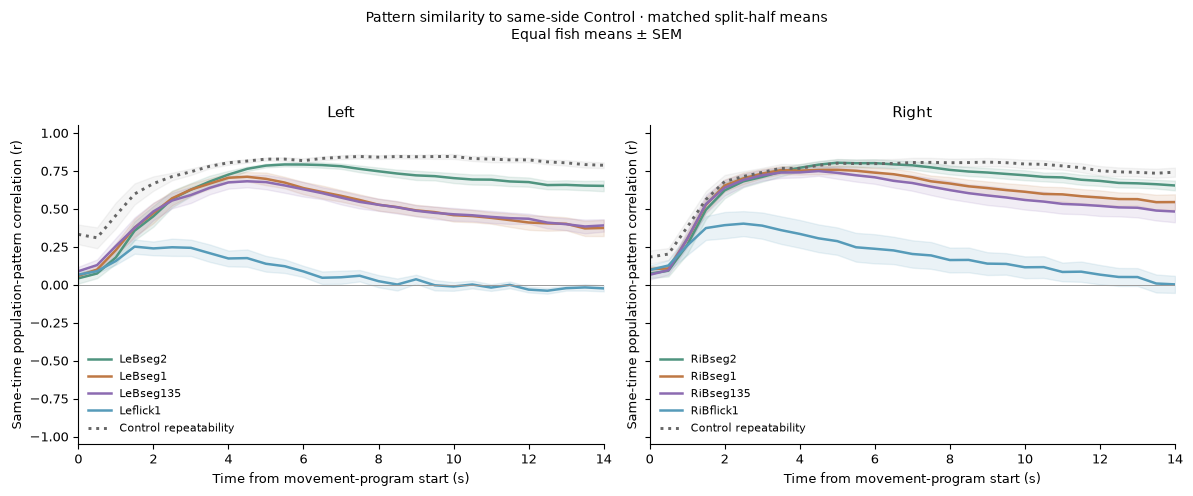

Saved SVG: exp08_population_pattern_similarity.svg


In [72]:
SAVE_SIMILARITY_SVG = True  # Save only this figure as SVG.
SIMILARITY_CURVE_FIGSIZE, SIMILARITY_FONT_PT = (12, 5), 9
COMBINE_SIMILARITY_SIDES = False
SHOW_SIMILARITY_SEM = True
SHOW_CONTROL_REPEATABILITY = True
similarity_curve_plot = population_plot.plot_control_similarity_curves(
    pattern_similarity, DISPLAY_STIMULI, colors=CONDITION_COLORS,
    combine_sides=COMBINE_SIMILARITY_SIDES, show_sem=SHOW_SIMILARITY_SEM,
    show_repeatability=SHOW_CONTROL_REPEATABILITY,
    figsize=SIMILARITY_CURVE_FIGSIZE, font_size=SIMILARITY_FONT_PT,
)
display(similarity_curve_plot['figure'])
if SAVE_SIMILARITY_SVG:
    saved_svg = plot_common.save_publication_figure(
        similarity_curve_plot['figure'], SVG_DIR / 'exp08_population_pattern_similarity', formats=('svg',),
    )
    print(f'Saved SVG: {saved_svg[0].name}')
plt.close(similarity_curve_plot['figure'])

## Optional audit: equal-count neuron sampling and physical stimulus differences

Repeat equal-count random neuron draws (minimum valid count per fish). A draw
uses the same neuron identities across conditions, time and repetitions. The
5–95% interval describes neuron-sampling sensitivity, not uncertainty across
independent fish. This is separate from the fish-level SEM in the main plot.
Trajectory CSV coordinate/radius differences are asset-derived times, not measured
monitor timing or causal explanations. Neither audit changes the display basis.

In [73]:
RUN_SUBSAMPLING = True
SUBSAMPLING_DRAWS, SUBSAMPLING_SEED = 50, 8
subsampling_result = (
    population.check_population_subsampling(
        trajectory_result, n_draws=SUBSAMPLING_DRAWS, seed=SUBSAMPLING_SEED,
    ) if RUN_SUBSAMPLING else None
)
if subsampling_result is not None:
    display(subsampling_result.loc[np.isclose(subsampling_result.time_s, 8.0),
        ['side', 'condition_a', 'condition_b', 'neurons_per_fish', 'all_neuron_distance',
         'subsample_median', 'subsample_p05', 'subsample_p95']].round(3))

,side,condition_a,condition_b,neurons_per_fish,all_neuron_distance,subsample_median,subsample_p05,subsample_p95
18,left,LeB,LeBseg2,192,8.888,8.953,7.968,9.655
49,left,LeB,LeBseg1,192,31.667,31.706,29.765,33.800
80,left,LeB,LeBseg135,192,32.036,31.889,30.150,34.020
111,left,LeB,LeRock,192,49.297,49.248,46.592,52.253
142,left,LeB,Leflick1,192,62.306,62.012,59.250,65.368
173,right,RiB,RiBseg2,192,4.579,4.609,4.078,5.259
204,right,RiB,RiBseg1,192,12.244,12.091,11.342,13.361
235,right,RiB,RiBseg135,192,17.211,16.994,16.095,18.513
266,right,RiB,RiBrock,192,33.259,33.256,31.654,35.742
297,right,RiB,RiBflick1,192,46.384,46.539,44.383,49.930


In [74]:
stimulus_event_rows = []
for side, config in SIDE_CONDITIONS.items():
    for a, b in config['pairs']:
        compared = timeline.first_trajectory_difference(
            stimuli_path / f'{a}_trajectory.csv', stimuli_path / f'{b}_trajectory.csv',
            framerate=TRAJECTORY_FPS,
        )
        stimulus_event_rows.append({'side': side, 'condition_a': a, 'condition_b': b,
            'first_stimulus_difference_s': compared['time_from_appearance_s'] - PROGRAM_ONSET_S})
stimulus_event_table = pd.DataFrame(stimulus_event_rows)
display(stimulus_event_table.round(3))

,side,condition_a,condition_b,first_stimulus_difference_s
0,left,LeB,LeBseg2,-8.0
1,left,LeB,LeBseg1,-8.0
2,left,LeB,LeBseg135,-8.0
3,left,LeB,LeRock,-8.0
4,left,LeB,Leflick1,-8.0
5,right,RiB,RiBseg2,-8.0
6,right,RiB,RiBseg1,-8.0
7,right,RiB,RiBseg135,-8.0
8,right,RiB,RiBrock,-8.0
9,right,RiB,RiBflick1,-8.0
